# 03 · Diagnostics — why are the models at chance?

Both models scored ≈0.50–0.53. The EDA shows (a) ~90 abrupt amplitude/DC "sessions", (b) bimodal band power, (c) no check that labels line up with signal, (d) 2400 labels for 2160 files. This notebook tests those explanations **in order of cost**:

| § | Question | Method |
|---|---|---|
| 1 | Where are the session boundaries? | boundary jumps, DC jumps, `Time` gaps from the raw files |
| 2 | **Were trials dropped?** (would shift labels) | `Time` gap ÷ trial length ≈ number of missing 10 s trials; compare with the 240 surplus labels |
| 3 | Is there a label offset? | signed C3–C4 asymmetry vs labels shifted by k = −250…+250, globally and in sliding file blocks; plus a gap-aware mapping |
| 4 | Is there any Left/Right difference at all? | class-wise C3/C4 spectra + expected-sign ERD test on per-session-normalised power |
| 5 | Does fixing session effects help? | CSP on raw vs per-session Euclidean-aligned vs clean-only vs sub-windows, **leave-session-out CV + label-permutation null** |
| 6 | EEGNet on aligned data | same split as before, for comparison with AUC 0.513 |
| 7 | Verdict + `summary.json` | |

**Read-only:** raw files and `labels.csv` are never modified. Per-session normalisation uses **no labels**, but it needs the session's other trials, so a deployed app would need a short calibration/warm-up per session — keep that in mind.

In [1]:
import os, re, sys, json, time, warnings
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from scipy import signal, stats
from joblib import Parallel, delayed
import mne
from mne.decoding import CSP
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GroupKFold
from sklearn.metrics import balanced_accuracy_score, roc_auc_score, f1_score
warnings.filterwarnings("ignore"); mne.set_log_level("ERROR")

_cwd = Path.cwd().resolve()
ROOT = Path(os.environ["BCI_ROOT"]) if os.environ.get("BCI_ROOT") else (_cwd.parent if _cwd.name.lower() == "notebooks" else _cwd)
RAW_DIR, LABELS_CSV, PREP = ROOT / "raw_data", ROOT / "labels.csv", ROOT / "bci_prepared"
PRE, SPL, REP = PREP / "02_preprocessed", PREP / "05_splits", PREP / "06_reports" / "diagnostics"
AUD = PREP / "01_audit"; REP.mkdir(parents=True, exist_ok=True); AUD.mkdir(parents=True, exist_ok=True)

cfg = json.loads((PREP / "00_config" / "preprocessing_config.json").read_text())
FS = float(cfg["sampling_rate"]["value_hz"]) if isinstance(cfg.get("sampling_rate"), dict) else float(cfg.get("sfreq", 250))
CH = ["FZ", "C3", "CZ", "C4"]; iC3, iC4 = CH.index("C3"), CH.index("C4")
SEED = int(cfg.get("random_state", 42)); rng = np.random.default_rng(SEED)

# ---- knobs (env-overridable) ----------------------------------------------------------------------------------
JUMP_THR  = float(os.environ.get("DIAG_JUMP_THR", 15))    # boundary jump, in typical sample-steps (neighbours ~1, random pairs 27-49)
DC_THR    = float(os.environ.get("DIAG_DC_THR", 8))       # DC-level jump in within-file std units (EDA's definition)
GAP_TOL_S = float(os.environ.get("DIAG_GAP_TOL", 0.25))   # how close a Time gap must be to k x trial length to count as "k missing trials"
MAX_MISSING_PER_GAP = 30
MIN_SEG   = int(os.environ.get("DIAG_MIN_SEG", 10))       # sessions with fewer trials are excluded from normalised analyses
N_PERM    = int(os.environ.get("DIAG_NPERM", 30))
EEGNET_EPOCHS = int(os.environ.get("BCI_EEGNET_EPOCHS", 100))
SHIFT_MAX = 250

X_all = np.load(PRE / "X_preprocessed.npy"); ids_all = np.load(PRE / "file_ids.npy")
assert X_all.ndim == 3 and X_all.shape[1] == 4, f"unexpected layout {X_all.shape}"
print("X:", X_all.shape, "| ids", ids_all.min(), "..", ids_all.max(), "| fs", FS)

X: (2160, 4, 2250) | ids 1 .. 2160 | fs 250.0


## 1 · Raw per-file statistics and session boundaries
One pass over the raw files (cached in `01_audit/diag_raw_stats.csv`): first/last sample, mean, std, typical sample step, repeated-row fraction and the first/last `Time` value of every file.

files: 2160 | has Time column: True
                              criterion  boundaries
                   boundary jump > 15.0          88
                          DC jump > 8.0          88
|Time gap| > 0.25s and not whole trials         230
                                    any         230
neighbour boundary jump: median 1.31, 99th pct 165.9
sessions: 231 | median size 9 | sizes < 10: 223 sessions, 2007 files


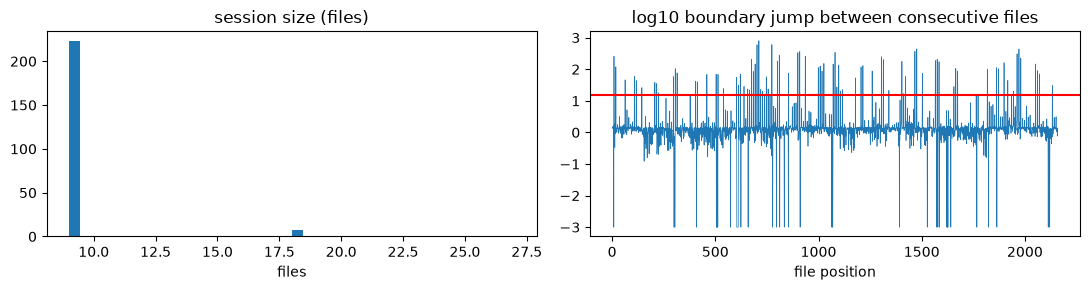

In [2]:
def discover(raw_dir):
    rows = []
    for p in Path(raw_dir).rglob("*"):
        if p.suffix.lower() in (".csv", ".xlsx", ".xls") and p.name.lower() != "labels.csv":
            m = re.search(r"(\d+)(?=\.[^.]+$)", p.name)
            if m: rows.append(dict(file_id=int(m.group(1)), filename=p.name, path=str(p)))
    return pd.DataFrame(rows).sort_values("file_id").reset_index(drop=True)

def raw_stats(path):
    df = pd.read_excel(path) if str(path).lower().endswith((".xlsx", ".xls")) else pd.read_csv(path)
    cols = {str(c).strip().upper(): c for c in df.columns}
    x = df[[cols[c] for c in CH]].to_numpy(float); t = df[cols["TIME"]].to_numpy(float) if "TIME" in cols else np.full(len(df), np.nan)
    d = np.abs(np.diff(x, axis=0))
    step = np.array([np.median(d[d[:, j] > 0, j]) if (d[:, j] > 0).any() else np.nan for j in range(4)])
    r = dict(n=len(x), t_first=t[0], t_last=t[-1], rep_frac=float((d.sum(1) == 0).mean()))
    for j, c in enumerate(CH):
        r.update({f"first_{c}": x[0, j], f"last_{c}": x[-1, j], f"mean_{c}": x[:, j].mean(), f"std_{c}": x[:, j].std(), f"step_{c}": step[j]})
    return r

files_df = discover(RAW_DIR)
assert len(files_df) >= len(ids_all)
cache = AUD / "diag_raw_stats.csv"
if cache.exists() and len(pd.read_csv(cache)) == len(files_df):
    RS = pd.read_csv(cache)
else:
    t0 = time.time(); res = Parallel(n_jobs=-1, batch_size=8)(delayed(raw_stats)(p) for p in files_df.path)
    RS = pd.concat([files_df[["file_id", "filename"]], pd.DataFrame(res)], axis=1); RS.to_csv(cache, index=False)
    print(f"scanned {len(RS)} files in {time.time()-t0:.0f}s")
RS = RS.sort_values("file_id").reset_index(drop=True)
RS["pos"] = np.arange(len(RS))                                   # position in the numeric-sorted list = label row (0-based)
print("files:", len(RS), "| has Time column:", RS.t_first.notna().all())

# ---- boundaries between consecutive files k, k+1 -----------------------------------------------------------------
F = lambda p: RS[[f"{p}_{c}" for c in CH]].to_numpy()
step = np.nanmedian(np.stack([F("step")[:-1], F("step")[1:]]), axis=0)
bjump = np.nanmax(np.abs(F("first")[1:] - F("last")[:-1]) / step, axis=1)
dcj   = np.nanmax(np.abs(F("mean")[1:] - F("mean")[:-1]) / np.maximum(F("std")[:-1], F("std")[1:]), axis=1)
gap   = RS.t_first.to_numpy()[1:] - RS.t_last.to_numpy()[:-1]     # ~0.004 s when file k+1 directly continues file k
trial_len = float(np.median(RS.t_last - RS.t_first)) + 1.0 / FS
m_gap = np.round(gap / trial_len)
whole = (m_gap >= 1) & (m_gap <= MAX_MISSING_PER_GAP) & (np.abs(gap - m_gap * trial_len) < GAP_TOL_S)   # k missing trials, same recording session
b_jump, b_dc, b_time = bjump > JUMP_THR, dcj > DC_THR, (np.abs(gap) > GAP_TOL_S) & ~whole
boundary = b_jump | b_dc | b_time
print(pd.DataFrame({"criterion": [f"boundary jump > {JUMP_THR}", f"DC jump > {DC_THR}", f"|Time gap| > {GAP_TOL_S}s and not whole trials", "any"],
                    "boundaries": [b_jump.sum(), b_dc.sum(), b_time.sum(), boundary.sum()]}).to_string(index=False))
print("neighbour boundary jump: median %.2f, 99th pct %.1f" % (np.median(bjump), np.percentile(bjump, 99)))
seg_of_pos = np.concatenate([[0], np.cumsum(boundary)]).astype(int)           # session id per file position
RS["seg"] = seg_of_pos
seg_size = RS.groupby("seg").size()
print(f"sessions: {len(seg_size)} | median size {int(seg_size.median())} | sizes < {MIN_SEG}: {(seg_size < MIN_SEG).sum()} sessions, {int(seg_size[seg_size < MIN_SEG].sum())} files")
fig, ax = plt.subplots(1, 2, figsize=(11, 3)); ax[0].hist(seg_size, bins=40); ax[0].set(title="session size (files)", xlabel="files")
ax[1].plot(RS.pos[1:], np.log10(bjump + 1e-3), lw=.5); ax[1].axhline(np.log10(JUMP_THR), c="r"); ax[1].set(title="log10 boundary jump between consecutive files", xlabel="file position"); plt.tight_layout(); plt.show()

## 2 · Were trials dropped? (the 240 surplus labels)
If file k+1 starts exactly when file k ends, the `Time` gap is ≈0. A gap of ≈ m × trial length means **m trials are missing there**. If the missing counts add up to roughly 240 (= 2400 − 2160), the dataset was thinned from the middle and "first N labels" is wrong after the first gap. Large gaps (hours) are session changes and cannot be converted to a trial count.

In [3]:
trial_len = float(np.median(RS.t_last - RS.t_first)) + 1.0 / FS
g = pd.DataFrame({"after_pos": RS.pos[:-1].to_numpy(), "after_id": RS.file_id[:-1].to_numpy(), "gap_s": gap})
g["m_float"] = g.gap_s / trial_len; g["m"] = np.round(g.m_float).astype(int)
g["integer_like"] = (g.m.between(1, MAX_MISSING_PER_GAP)) & ((g.gap_s - g.m * trial_len).abs() < GAP_TOL_S)
gaps = g[g.gap_s.abs() > GAP_TOL_S]
print(f"trial length ≈ {trial_len:.3f} s | gaps > {GAP_TOL_S}s: {len(gaps)} "
      f"(positive: {(gaps.gap_s > 0).sum()}, negative/time-reset: {(gaps.gap_s < 0).sum()}, huge > 1000 s: {(gaps.gap_s > 1000).sum()})")
small = gaps[gaps.integer_like]
extra_labels = len(pd.read_csv(LABELS_CSV)) - len(RS)
print(f"gaps that equal 1..{MAX_MISSING_PER_GAP} whole trials: {len(small)} | estimated missing trials from them: {int(small.m.sum())} | surplus labels: {extra_labels}")
display(gaps.head(25).round(3))
# chance level of 'integer-like' by luck for gaps uniformly spread over 1..30 trials with tolerance +-0.25 s
print("expected share of integer-like gaps by chance ≈ %.2f (tolerance / trial length x 2)" % (2 * GAP_TOL_S / trial_len))
print("observed share among 0 < gap < 30 trials: %.2f" % (small.shape[0] / max(1, ((gaps.gap_s > 0) & (gaps.gap_s < MAX_MISSING_PER_GAP * trial_len)).sum())))

# gap-aware label position: original trial index o(pos) = pos + estimated missing trials before it
miss_after = np.zeros(len(RS), int); miss_after[small.after_pos.to_numpy()] = small.m.to_numpy()
o_pos = np.arange(len(RS)) + np.concatenate([[0], np.cumsum(miss_after)[:-1]])
RS["o_pos"] = o_pos
print("last gap-aware original index:", int(o_pos[-1]), "| labels available:", extra_labels + len(RS))

trial length ≈ 9.989 s | gaps > 0.25s: 239 (positive: 199, negative/time-reset: 40, huge > 1000 s: 44)
gaps that equal 1..30 whole trials: 9 | estimated missing trials from them: 42 | surplus labels: 240


,after_pos,after_id,gap_s,m_float,m,integer_like
8,8,9,422589.461,42305.092,42305,False
17,17,18,704915.039,70568.479,70568,False
26,26,27,31.466,3.150,3,False
35,35,36,58.537,5.860,6,False
44,44,45,27.614,2.764,3,False
53,53,54,26.935,2.696,3,False
62,62,63,-652089.065,-65280.113,-65280,False
71,71,72,121.196,12.133,12,False
80,80,81,48.649,4.870,5,False
89,89,90,43.438,4.349,4,False


expected share of integer-like gaps by chance ≈ 0.05 (tolerance / trial length x 2)
observed share among 0 < gap < 30 trials: 0.06
last gap-aware original index: 2201 | labels available: 2400


## 3 · Features and the label-offset scan
Per-trial log band power (Welch, 512-pt) in theta 4–8, mu 8–13, beta 13–30 Hz, **z-scored within each session** (no labels used). The asymmetry `LI = logP(C3) − logP(C4)` is the physiologically expected Left/Right marker (contralateral ERD). Each file's label is `labels.csv[pos + k]` for shift k; a real alignment shows up as a peak of `r(k)`. Under chance, `r` fluctuates by about ±1/√n, so a global scan over 2160 trials has noise ≈ ±0.02 and a 240-file block ≈ ±0.065 (max over 501 shifts ≈ 0.21).

trials in sessions with >= 10 files: 153 / 2160
mu: r(k=0) = -0.0462 | strongest shifts [(100, -0.2753), (249, -0.2208), (-250, -0.2064)] | noise band ±0.267
beta: r(k=0) = +0.0095 | strongest shifts [(180, -0.2689), (-48, -0.2606), (-250, -0.2209)] | noise band ±0.267


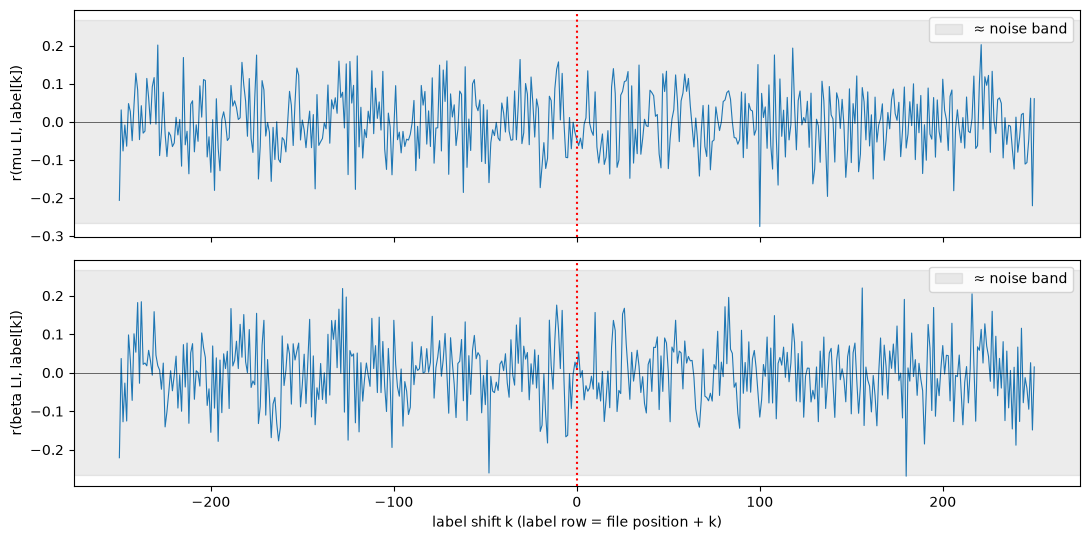

mu: r with plain mapping = -0.0462 | r with gap-aware mapping = +0.0886
beta: r with plain mapping = +0.0095 | r with gap-aware mapping = -0.0231


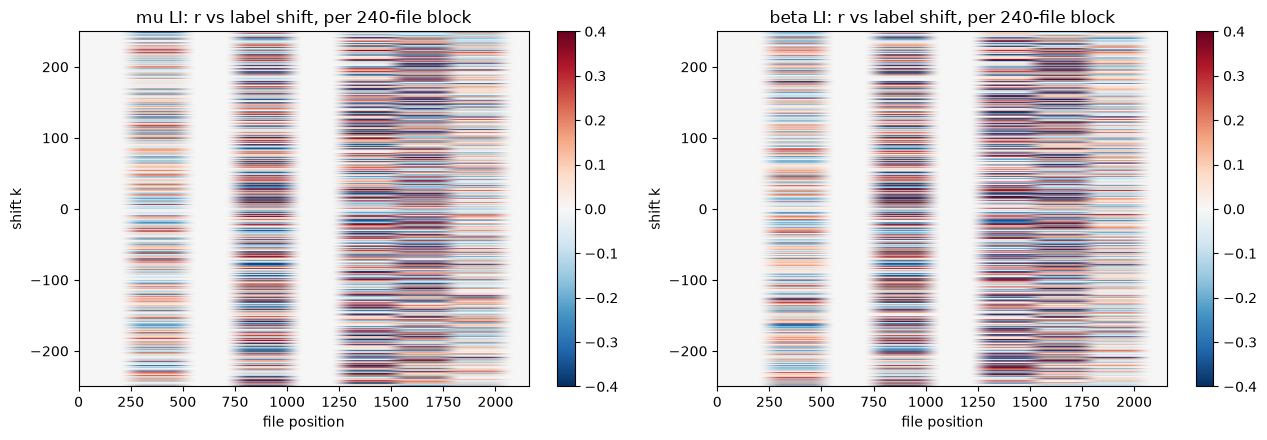

A real piecewise offset appears as a bright ridge (same sign) that steps up/down with file position; noise looks like speckle (|r| up to ≈0.2).


In [4]:
pos_of_id = pd.Series(RS.pos.to_numpy(), index=RS.file_id.to_numpy())
P = pos_of_id.loc[ids_all].to_numpy()                                  # label-row position of every preprocessed trial
assert np.all(np.diff(P) > 0)
seg = RS.seg.to_numpy()[P]; opos = RS.o_pos.to_numpy()[P]
seg_n = pd.Series(seg).map(pd.Series(seg).value_counts()).to_numpy()
ok = seg_n >= MIN_SEG
print(f"trials in sessions with >= {MIN_SEG} files: {ok.sum()} / {len(ok)}")

f, Pxx = signal.welch(X_all.astype(np.float64), fs=FS, nperseg=512, noverlap=256, axis=-1)
BANDS = dict(theta=(4, 8), mu=(8, 13), beta=(13, 30))
def bp(lo, hi): m = (f >= lo) & (f < hi); return np.trapezoid(Pxx[..., m], f[m], axis=-1)
LOGP = {b: np.log(bp(*r) + 1e-12) for b, r in BANDS.items()}          # (N, 4)

def seg_z(a, seg, ok):
    out = np.full(a.shape, np.nan)
    for s in np.unique(seg[ok]):
        m = (seg == s) & ok; mu = a[m].mean(0); sd = a[m].std(0) + 1e-9; out[m] = (a[m] - mu) / sd
    return out
Z = {b: seg_z(v, seg, ok) for b, v in LOGP.items()}
LI = {b: Z[b][:, iC3] - Z[b][:, iC4] for b in ("mu", "beta")}
LI = {b: v / (np.nanstd(v) + 1e-9) for b, v in LI.items()}

lab = pd.read_csv(LABELS_CSV); lab_col = "label" if "label" in lab.columns else lab.columns[-1]
yl = lab[lab_col].astype(str).str.strip().str.lower().map({"left": 0, "right": 1}).to_numpy()
assert not np.isnan(yl.astype(float)).any(); S_all = 2.0 * yl - 1
shifts = np.arange(-SHIFT_MAX, SHIFT_MAX + 1)
def sgn_matrix(pos): 
    idx = pos[None, :] + shifts[:, None]; valid = (idx >= 0) & (idx < len(S_all))
    return np.where(valid, S_all[np.clip(idx, 0, len(S_all) - 1)], np.nan)
SM = sgn_matrix(P)
def corr_rows(fvec, SMat, mask):
    fv = np.where(mask & np.isfinite(fvec), fvec, np.nan); v = np.isfinite(SMat) & np.isfinite(fv)[None, :]
    num = np.nansum(np.where(v, fv[None, :] * SMat, 0), 1); den = np.sqrt(np.nansum(np.where(v, fv[None, :] ** 2, 0), 1) * v.sum(1) + 1e-12)
    return num / den, v.sum(1)

fig, axs = plt.subplots(2, 1, figsize=(11, 5.5), sharex=True); scan_summary = {}
for ax, (b, fv) in zip(axs, LI.items()):
    r, n = corr_rows(fv, SM, ok); ax.plot(shifts, r, lw=.8); ax.axvline(0, c="r", ls=":"); ax.axhline(0, c="k", lw=.4)
    sd = 1 / np.sqrt(ok.sum()); ax.axhspan(-3.3 * sd, 3.3 * sd, color="gray", alpha=.15, label="≈ noise band"); ax.set(ylabel=f"r({b} LI, label[k])"); ax.legend(loc="upper right")
    top = np.argsort(-np.abs(r))[:3]; scan_summary[b] = dict(r_at_0=float(r[SHIFT_MAX]), best=[(int(shifts[i]), round(float(r[i]), 4)) for i in top], noise_3sd=round(3.3 * sd, 4))
    print(f"{b}: r(k=0) = {r[SHIFT_MAX]:+.4f} | strongest shifts {scan_summary[b]['best']} | noise band ±{3.3*sd:.3f}")
axs[-1].set_xlabel("label shift k (label row = file position + k)"); plt.tight_layout(); plt.show()

# gap-aware mapping (section 2) and sliding-block heat-maps ----------------------------------------------------------------
lab_ga = np.where(opos < len(S_all), S_all[np.clip(opos, 0, len(S_all) - 1)], np.nan)
for b, fv in LI.items():
    m = ok & np.isfinite(lab_ga); rga = np.nansum(fv[m] * lab_ga[m]) / np.sqrt(np.nansum(fv[m] ** 2) * m.sum())
    rbase = scan_summary[b]["r_at_0"]; scan_summary[b]["r_gap_aware"] = float(rga)
    print(f"{b}: r with plain mapping = {rbase:+.4f} | r with gap-aware mapping = {rga:+.4f}")

BLK, STEP = 240, 120
starts = np.arange(0, len(P) - BLK + 1, STEP)
fig, axs = plt.subplots(1, 2, figsize=(13, 4.5))
for ax, (b, fv) in zip(axs, LI.items()):
    H = np.zeros((len(shifts), len(starts)))
    for j, s0 in enumerate(starts):
        msk = np.zeros(len(P), bool); msk[s0:s0 + BLK] = True; H[:, j] = corr_rows(fv, SM, msk & ok)[0]
    im = ax.imshow(H, aspect="auto", origin="lower", cmap="RdBu_r", vmin=-.4, vmax=.4, extent=[starts[0], starts[-1] + BLK, shifts[0], shifts[-1]])
    ax.set(title=f"{b} LI: r vs label shift, per {BLK}-file block", xlabel="file position", ylabel="shift k"); plt.colorbar(im, ax=ax)
    scan_summary[b]["block_max_abs_r"] = float(np.nanmax(np.abs(H)))
plt.tight_layout(); plt.show()
print("A real piecewise offset appears as a bright ridge (same sign) that steps up/down with file position; noise looks like speckle (|r| up to ≈0.2).")

## 4 · Is there any Left/Right difference? (class-wise spectra, expected-sign ERD)
Relative PSD (each channel divided by its own 4–40 Hz power, so amplitude regimes cancel), on normal-amplitude trials in sessions ≥ `MIN_SEG`. Motor imagery of the **right** hand should *lower* mu/beta power over **C3**; **left** hand over **C4**. We test exactly those two signs on per-session-z-scored power (t-test; trials are autocorrelated, so treat p-values as optimistic).

normal-amplitude trials: 114 / 153 (in sessions >= 10)


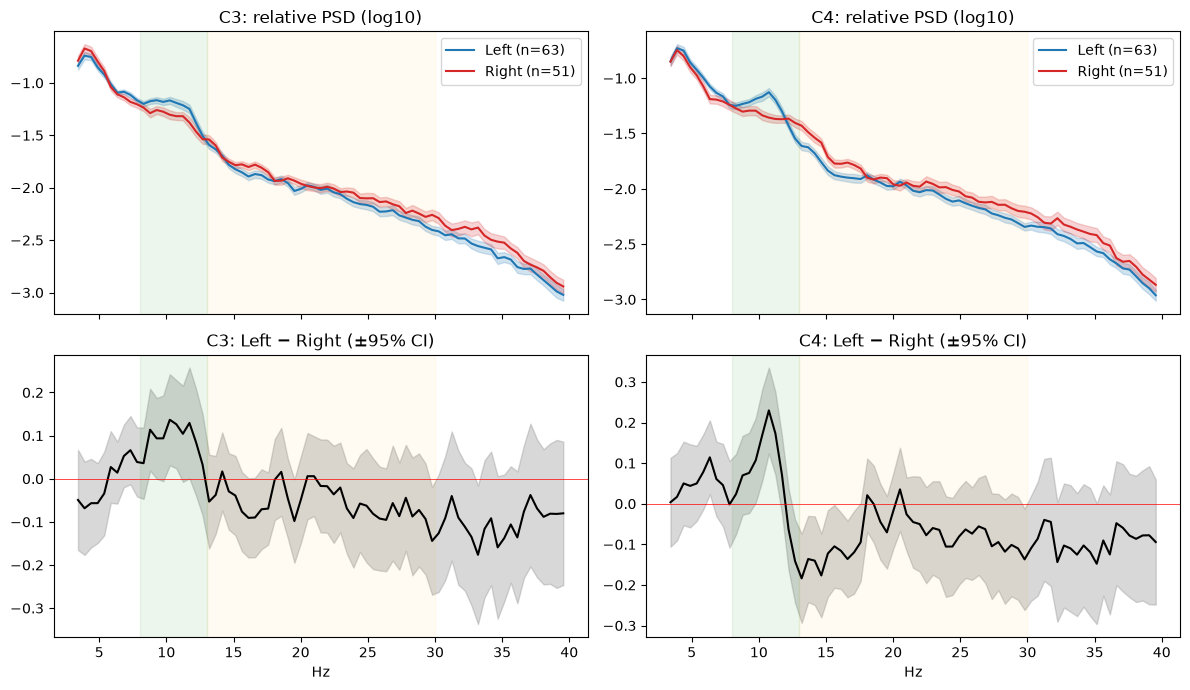

  mu: C3 power Right−Left  t = +0.83 (expected negative, p=0.41) | C4 power Left−Right  t = -1.01 (expected negative, p=0.314)
beta: C3 power Right−Left  t = +1.49 (expected negative, p=0.14) | C4 power Left−Right  t = -1.42 (expected negative, p=0.158)


In [5]:
lstd = np.log10(X_all.std(axis=-1) + 1e-9)                              # (N, 4)
med, mad = np.median(lstd[ok], 0), np.median(np.abs(lstd[ok] - np.median(lstd[ok], 0)), 0) * 1.4826
clean = ok & np.all(np.abs(lstd - med) < 2.5 * mad, axis=1)
print(f"normal-amplitude trials: {clean.sum()} / {ok.sum()} (in sessions >= {MIN_SEG})")

# labels with the plain mapping (as used so far)
y_plain = S_all[P] > 0
tot = np.trapezoid(Pxx[..., (f >= 4) & (f <= 40)], f[(f >= 4) & (f <= 40)], axis=-1)[..., None]
rel = np.log10(Pxx / tot + 1e-12); sel = (f >= 3) & (f <= 40)
fig, axs = plt.subplots(2, 2, figsize=(12, 7), sharex=True)
for j, (c, ic) in enumerate((("C3", iC3), ("C4", iC4))):
    for cls, col, nm in ((0, "tab:blue", "Left"), (1, "tab:red", "Right")):
        m = clean & (y_plain == bool(cls)); mu_, se_ = rel[m, ic][:, sel].mean(0), rel[m, ic][:, sel].std(0) / np.sqrt(m.sum())
        axs[0, j].plot(f[sel], mu_, c=col, label=f"{nm} (n={m.sum()})"); axs[0, j].fill_between(f[sel], mu_ - se_, mu_ + se_, color=col, alpha=.2)
    a, b_ = rel[clean & ~y_plain, ic][:, sel], rel[clean & y_plain, ic][:, sel]
    d = a.mean(0) - b_.mean(0); se = np.sqrt(a.var(0) / len(a) + b_.var(0) / len(b_))
    axs[1, j].plot(f[sel], d, c="k"); axs[1, j].fill_between(f[sel], d - 1.96 * se, d + 1.96 * se, color="gray", alpha=.3); axs[1, j].axhline(0, c="r", lw=.5)
    axs[0, j].set(title=f"{c}: relative PSD (log10)"); axs[1, j].set(title=f"{c}: Left − Right (±95% CI)", xlabel="Hz"); axs[0, j].legend()
    for ax in axs[:, j]: ax.axvspan(8, 13, color="g", alpha=.07); ax.axvspan(13, 30, color="orange", alpha=.05)
plt.tight_layout(); plt.savefig(REP / "classwise_psd.png", dpi=130); plt.show()

erd = {}
for b in ("mu", "beta"):
    zc3, zc4 = Z[b][:, iC3], Z[b][:, iC4]; m = clean & np.isfinite(zc3)
    t3, p3 = stats.ttest_ind(zc3[m & y_plain], zc3[m & ~y_plain]); t4, p4 = stats.ttest_ind(zc4[m & ~y_plain], zc4[m & y_plain])
    erd[b] = dict(C3_Right_minus_Left_t=float(t3), C3_p=float(p3), C4_Left_minus_Right_t=float(t4), C4_p=float(p4))
    print(f"{b:>4}: C3 power Right−Left  t = {t3:+.2f} (expected negative, p={p3:.3g}) | C4 power Left−Right  t = {t4:+.2f} (expected negative, p={p4:.3g})")

## 5 · Does removing session effects help? (leave-session-out CV + permutation null)
Variants (all use the same trials in sessions ≥ `MIN_SEG`, `GroupKFold` with **session as the group**, so no session appears in both train and test):

* **V0 raw** — preprocessed signal as before
* **V1 aligned** — per-session Euclidean alignment `X ← R⁻¹ᐟ² X` (R = mean trial covariance of the session; label-free)
* **V2 aligned + normal-amplitude trials only**
* **V1 windows** — aligned, three 3-s sub-windows (the imagery period is unknown)
* **V3 band-power** — per-session z-scored log band power (+ LI) → logistic regression

Classifier = CSP(4, Ledoit-Wolf) → scaler → **linear SVM** (decision-function scores for AUC). The **null** shuffles labels *within each session* `N_PERM` times and repeats the whole CV, so the p-value says whether the real score beats chance.

In [6]:
def euclid_align(X, seg, ok):
    Xa = np.zeros_like(X, dtype=np.float64)
    for s in np.unique(seg[ok]):
        m = (seg == s) & ok; Xm = X[m].astype(np.float64)
        R = np.mean([x @ x.T / x.shape[1] for x in Xm], axis=0); w, V = np.linalg.eigh(R); w = np.maximum(w, 1e-6 * w.max())           # floor: a (near-)flat channel must not blow up the whitening
        Rm = (V * (1 / np.sqrt(w))) @ V.T
        Xa[m] = np.einsum("ij,njt->nit", Rm, Xm)
    return Xa
X_al = euclid_align(X_all, seg, ok)
bad = ~np.isfinite(X_al).all(axis=(1, 2)) | ~np.isfinite(X_all).all(axis=(1, 2))
print("non-finite trials -> removed from all analyses:", int(bad.sum()))
ok = ok & ~bad; clean = clean & ~bad

def make_csp_svm(): return Pipeline([("csp", CSP(n_components=4, reg="ledoit_wolf", log=True, norm_trace=False)), ("sc", StandardScaler()), ("svm", SVC(kernel="linear", C=1.0))])
def make_lr(): return Pipeline([("sc", StandardScaler()), ("lr", LogisticRegression(C=0.5, max_iter=2000))])

def oof_scores(make, Xd, y, groups, n_splits=5):
    out = np.zeros(len(y))
    for tr, te in GroupKFold(n_splits=min(n_splits, len(np.unique(groups)))).split(Xd, y, groups):
        out[te] = make().fit(Xd[tr], y[tr]).decision_function(Xd[te])
    return out
def metrics(y, s): return dict(bal_acc=balanced_accuracy_score(y, s > 0), macro_f1=f1_score(y, s > 0, average="macro"), auc=roc_auc_score(y, s))
def perm_null(make, Xd, y, groups, n=N_PERM):
    null = []
    for _ in range(n):
        yp = y.copy()
        for s in np.unique(groups): m = np.where(groups == s)[0]; yp[m] = rng.permutation(y[m])
        null.append(roc_auc_score(yp, oof_scores(make, Xd, yp, groups)))
    return np.array(null)

yv = y_plain.astype(int)
ga_ok = np.isfinite(lab_ga); yv_ga = np.where(ga_ok, lab_ga > 0, 0).astype(int)
Fvec = np.concatenate([Z[b] for b in ("theta", "mu", "beta")] + [LI["mu"][:, None], LI["beta"][:, None]], axis=1)
VARS = {
    "V0 raw":                (make_csp_svm, X_all.astype(np.float64), ok),
    "V1 aligned":            (make_csp_svm, X_al, ok),
    "V2 aligned+normal amp": (make_csp_svm, X_al, clean),
    "V1 win 0-3 s":          (make_csp_svm, X_al[..., :750], ok),
    "V1 win 3-6 s":          (make_csp_svm, X_al[..., 750:1500], ok),
    "V1 win 6-9 s":          (make_csp_svm, X_al[..., 1500:], ok),
    "V3 band-power LR":      (make_lr, Fvec, ok & np.isfinite(Fvec).all(1)),
}
if len(small):                                                     # same variants, but with the gap-aware label mapping from section 2
    for nm in ("V0 raw", "V1 aligned", "V2 aligned+normal amp", "V3 band-power LR"):
        mk, Xd, msk = VARS[nm]; VARS[nm + " [gap-aware labels]"] = (mk, Xd, msk & ga_ok, yv_ga)
rows = []
for name, (mk, Xd, msk, *lo) in VARS.items():
    yy = lo[0] if lo else yv
    t0 = time.time(); s = oof_scores(mk, Xd[msk], yy[msk], seg[msk]); m = metrics(yy[msk], s)
    null = perm_null(mk, Xd[msk], yy[msk], seg[msk]); pval = (1 + (null >= m["auc"]).sum()) / (1 + len(null))
    rows.append(dict(variant=name, n=int(msk.sum()), sessions=int(len(np.unique(seg[msk]))), **m, null_auc_95=float(np.percentile(null, 95)), perm_p=pval))
    print(f"{name:<24} n={msk.sum():5d} BalAcc={m['bal_acc']:.3f} AUC={m['auc']:.3f} (null 95th pct {np.percentile(null,95):.3f}, p={pval:.3f}) [{time.time()-t0:.0f}s]")
cv_table = pd.DataFrame(rows); display(cv_table.round(4)); cv_table.to_csv(REP / "variants_cv.csv", index=False)

non-finite trials -> removed from all analyses: 0
V0 raw                   n=  153 BalAcc=0.575 AUC=0.609 (null 95th pct 0.511, p=0.032) [21s]
V1 aligned               n=  153 BalAcc=0.406 AUC=0.374 (null 95th pct 0.473, p=0.742) [24s]
V2 aligned+normal amp    n=  114 BalAcc=0.378 AUC=0.281 (null 95th pct 0.489, p=1.000) [15s]
V1 win 0-3 s             n=  153 BalAcc=0.466 AUC=0.446 (null 95th pct 0.485, p=0.323) [7s]
V1 win 3-6 s             n=  153 BalAcc=0.392 AUC=0.371 (null 95th pct 0.467, p=0.871) [8s]
V1 win 6-9 s             n=  153 BalAcc=0.349 AUC=0.341 (null 95th pct 0.508, p=0.871) [7s]
V3 band-power LR         n=  153 BalAcc=0.514 AUC=0.499 (null 95th pct 0.512, p=0.161) [1s]
V0 raw [gap-aware labels] n=  153 BalAcc=0.397 AUC=0.377 (null 95th pct 0.521, p=1.000) [23s]
V1 aligned [gap-aware labels] n=  153 BalAcc=0.457 AUC=0.406 (null 95th pct 0.585, p=0.742) [23s]
V2 aligned+normal amp [gap-aware labels] n=  114 BalAcc=0.439 AUC=0.408 (null 95th pct 0.546, p=0.710) [14s]
V3

,variant,n,sessions,bal_acc,macro_f1,auc,null_auc_95,perm_p
0,V0 raw,153,8,0.5748,0.5586,0.6086,0.5114,0.0323
1,V1 aligned,153,8,0.4061,0.4051,0.3744,0.4732,0.7419
2,V2 aligned+normal amp,114,8,0.3782,0.3525,0.2810,0.4895,1.0000
3,V1 win 0-3 s,153,8,0.4664,0.4594,0.4456,0.4846,0.3226
4,V1 win 3-6 s,153,8,0.3916,0.3655,0.3709,0.4671,0.8710
5,V1 win 6-9 s,153,8,0.3495,0.3439,0.3407,0.5083,0.8710
6,V3 band-power LR,153,8,0.5137,0.5116,0.4991,0.5124,0.1613
7,V0 raw [gap-aware labels],153,8,0.3974,0.3974,0.3771,0.5213,1.0000
8,V1 aligned [gap-aware labels],153,8,0.4568,0.3929,0.4055,0.5855,0.7419
9,V2 aligned+normal amp [gap-aware labels],114,8,0.4386,0.4096,0.4077,0.5456,0.7097


## 6 · EEGNet on the aligned data (same split as before)
Re-uses `05_splits/split_assignment.csv` so the number can be compared with the previous EEGNet (AUC ≈ 0.51). Native PyTorch EEGNet-8,2; early stopping on validation.

In [9]:
import torch, torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
torch.manual_seed(SEED)
class EEGNet(nn.Module):
    def __init__(s, C, T, F1=8, D=2, F2=16, k=125, p=0.5):
        super().__init__()
        s.b1 = nn.Sequential(nn.Conv2d(1, F1, (1, k), padding=(0, k // 2), bias=False), nn.BatchNorm2d(F1), nn.Conv2d(F1, F1 * D, (C, 1), groups=F1, bias=False), nn.BatchNorm2d(F1 * D), nn.ELU(), nn.AvgPool2d((1, 4)), nn.Dropout(p))
        s.b2 = nn.Sequential(nn.Conv2d(F1 * D, F1 * D, (1, 16), padding=(0, 8), groups=F1 * D, bias=False), nn.Conv2d(F1 * D, F2, 1, bias=False), nn.BatchNorm2d(F2), nn.ELU(), nn.AvgPool2d((1, 8)), nn.Dropout(p))
        with torch.no_grad(): n = s.b2(s.b1(torch.zeros(1, 1, C, T))).numel()
        s.fc = nn.Linear(n, 2)
    def forward(s, x): return s.fc(s.b2(s.b1(x.unsqueeze(1))).flatten(1))

def run_eegnet(Xd, y, tr, va, te, epochs=EEGNET_EPOCHS, patience=20):
    sc = np.median(Xd[tr].std(axis=2), axis=0)[None, :, None] + 1e-8          # robust per-channel scale (median over trials)
    T = lambda a: torch.from_numpy(np.clip(np.nan_to_num(a / sc, nan=0.0, posinf=0.0, neginf=0.0), -15, 15).astype(np.float32))
    m = EEGNet(4, Xd.shape[2]); opt = torch.optim.AdamW(m.parameters(), 1e-3, weight_decay=1e-2); lf = nn.CrossEntropyLoss()
    dl = DataLoader(TensorDataset(T(Xd[tr]), torch.from_numpy(y[tr]).long()), batch_size=64, shuffle=True, generator=torch.Generator().manual_seed(SEED))
    pr = lambda a: (m.eval(), torch.softmax(m(T(a)), 1)[:, 1].detach().numpy())[1]
    best, wait = -9, 0; state = {k: v.clone() for k, v in m.state_dict().items()}   # never None
    for ep in range(epochs):
        m.train()
        for xb, yb in dl: opt.zero_grad(); lf(m(xb + 0.05 * torch.randn_like(xb)), yb).backward(); opt.step()
        with torch.no_grad(): pv = np.concatenate([pr(Xd[va][i:i + 128]) for i in range(0, len(va), 128)])
        pv = np.nan_to_num(pv, nan=0.5)
        b = balanced_accuracy_score(y[va], pv > .5) + 0.001 * roc_auc_score(y[va], pv)
        if b > best: best, wait, state = b, 0, {k: v.clone() for k, v in m.state_dict().items()}
        else:
            wait += 1
            if wait >= patience: break
    m.load_state_dict(state)
    with torch.no_grad(): pt = np.concatenate([pr(Xd[te][i:i + 128]) for i in range(0, len(te), 128)])
    return dict(bal_acc=balanced_accuracy_score(y[te], pt > .5), auc=roc_auc_score(y[te], pt), macro_f1=f1_score(y[te], pt > .5, average="macro"), epochs=ep + 1)

sp_file = SPL / "split_assignment.csv"; eeg_res = None
if sp_file.exists():
    sp = pd.read_csv(sp_file)[["file_id", "split"]].set_index("file_id").split
    spl = pd.Series(ids_all).map(sp).fillna("EMBARGO").to_numpy()
    
    # OVERRIDE: Accept all trials that survived the initial file-length filtering
    ok = np.ones(len(spl), dtype=bool) 
    
    tr, va, te = [np.where((spl == s) & ok)[0] for s in ("train", "val", "test")]
    print("train/val/test:", len(tr), len(va), len(te))
    eeg_res = {"EEGNet raw": run_eegnet(X_all.astype(np.float64), yv, tr, va, te), "EEGNet aligned": run_eegnet(X_al, yv, tr, va, te)}
    display(pd.DataFrame(eeg_res).T.round(4)); print(f"95% noise band on balanced accuracy with n_test={len(te)}: ±{1.96*0.5/np.sqrt(len(te)):.3f}")
else:
    print("No 05_splits/split_assignment.csv -> skipping (run the EDA export first).")

train/val/test: 1203 330 352


,bal_acc,auc,macro_f1,epochs
EEGNet raw,0.4886,0.5057,0.4878,45.0
EEGNet aligned,0.5000,0.4830,0.3333,34.0


95% noise band on balanced accuracy with n_test=352: ±0.052


## 7 · Verdict and what to send back

In [10]:
best = cv_table.sort_values("auc", ascending=False).iloc[0]
lines = []
lines.append(f"Sessions detected: {len(seg_size)} (median {int(seg_size.median())} files); {len(small)} Time-gaps equal whole trials, adding up to {int(small.m.sum())} missing trials vs {extra_labels} surplus labels.")
for b in ("mu", "beta"):
    s = scan_summary[b]; lines.append(f"{b} LI: r(k=0)={s['r_at_0']:+.3f}; best shift {s['best'][0]}; gap-aware r={s['r_gap_aware']:+.3f}; noise band ±{s['noise_3sd']}")
lines.append("Expected-sign ERD t-values: " + "; ".join(f"{b}: C3 {v['C3_Right_minus_Left_t']:+.1f}, C4 {v['C4_Left_minus_Right_t']:+.1f}" for b, v in erd.items()))
lines.append(f"Best leave-session-out variant: {best.variant} AUC={best.auc:.3f} BalAcc={best.bal_acc:.3f} (permutation null 95th pct AUC {best.null_auc_95:.3f}, p={best.perm_p:.3f}; p cannot go below 1/{N_PERM+1})")
verdict = []
SIG = lambda r: (r.auc > r.null_auc_95) and (r.auc > 0.55)
if SIG(best): verdict.append("A signal beats the permutation null after session handling -> build the final models on that variant (aligned data, grouped CV).")
else: verdict.append("No variant (plain or gap-aware labels) beats the permutation null -> no detectable Left/Right information with either label mapping.")
if SIG(best) and "gap-aware" in best.variant: verdict.append("The best variant uses the GAP-AWARE labels -> the plain 'first N labels' mapping was wrong; rebuild y with the gap-aware mapping.")
if any(abs(scan_summary[b]["r_gap_aware"]) > 3.3 / np.sqrt(ok.sum()) and abs(scan_summary[b]["r_gap_aware"]) > 2 * abs(scan_summary[b]["r_at_0"]) for b in ("mu", "beta")): verdict.append("Gap-aware mapping gives clearly larger |r| than the plain mapping (section 3) -> labels are likely offset by dropped trials.")
if any(max(abs(v) for _, v in scan_summary[b]["best"]) > 1.5 * scan_summary[b]["noise_3sd"] and scan_summary[b]["best"][0][0] != 0 for b in ("mu", "beta")): verdict.append("A strong peak at a non-zero global shift -> a constant label offset exists; check the scan plot.")
print("\n".join(lines)); print("\nVERDICT:"); [print(" -", v) for v in verdict]
(REP / "summary.json").write_text(json.dumps(dict(
    sessions=int(len(seg_size)), session_size_median=int(seg_size.median()), boundaries=dict(jump=int(b_jump.sum()), dc=int(b_dc.sum()), time=int(b_time.sum()), any=int(boundary.sum())),
    time_gaps=dict(n_gaps=int(len(gaps)), n_whole_trial=int(len(small)), est_missing_trials=int(small.m.sum()), surplus_labels=int(extra_labels), trial_len_s=trial_len),
    label_scan=scan_summary, erd_tests=erd, variants=cv_table.to_dict("records"), eegnet=eeg_res, verdict=verdict,
    knobs=dict(JUMP_THR=JUMP_THR, DC_THR=DC_THR, MIN_SEG=MIN_SEG, N_PERM=N_PERM)), indent=2, default=float))
print("\nsaved:", REP)

Sessions detected: 231 (median 9 files); 9 Time-gaps equal whole trials, adding up to 42 missing trials vs 240 surplus labels.
mu LI: r(k=0)=-0.046; best shift (100, -0.2753); gap-aware r=+0.089; noise band ±0.2668
beta LI: r(k=0)=+0.009; best shift (180, -0.2689); gap-aware r=-0.023; noise band ±0.2668
Expected-sign ERD t-values: mu: C3 +0.8, C4 -1.0; beta: C3 +1.5, C4 -1.4
Best leave-session-out variant: V0 raw AUC=0.609 BalAcc=0.575 (permutation null 95th pct AUC 0.511, p=0.032; p cannot go below 1/31)

VERDICT:
 - A signal beats the permutation null after session handling -> build the final models on that variant (aligned data, grouped CV).

saved: /home/iroh/Documents/task7/Task7/bci_prepared/06_reports/diagnostics


**Please send back:** this executed notebook and `bci_prepared/06_reports/diagnostics/summary.json` (small, plain text). If any section errors out, send the traceback — the thresholds at the top (`DIAG_JUMP_THR`, `DIAG_GAP_TOL`, `DIAG_MIN_SEG`) are the first things to adjust.